# Decision Tree profitability model

This notebook uses a simple sequence: load data, split data, fill missing values, train a tree, choose a validation threshold, evaluate the test data, and plot the results.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.metrics import accuracy_score, average_precision_score, ConfusionMatrixDisplay, PrecisionRecallDisplay, RocCurveDisplay, f1_score, precision_score, recall_score, roc_auc_score, confusion_matrix
from sklearn.model_selection import cross_validate, cross_val_predict
from sklearn.tree import DecisionTreeClassifier
from sklearn.model_selection import RandomizedSearchCV, StratifiedKFold
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer, make_column_selector
from sklearn.impute import SimpleImputer
import preprocessing

## Load and inspect the prepared records

The CSV contains 134 predictor columns and the binary `profitable` target. Profit is 1 and Loss is 0. The classes are balanced because the source data was undersampled.

In [2]:
df = pd.read_csv(preprocessing.TRAIN_DATA_PATH, low_memory=False)
X = df.drop(columns=["profitable"])
y = df["profitable"]
print("Feature shape:", X.shape)
print("Class balance:\n", y.value_counts())

Feature shape: (439339, 134)
Class balance:
 profitable
1    219670
0    219669
Name: count, dtype: int64


## Define training and test sets using the separated datasets from Datavisualization

The test set is held out until the end. Stratification keeps the Profit/Loss proportions consistent. Parameter selection and threshold selection use only the training set and the shared five-fold cross-validation splits.

In [3]:
test_df = pd.read_csv(preprocessing.TEST_DATA_PATH, low_memory=False)
X_train, y_train = X, y
X_test = test_df.drop(columns=["profitable"])
y_test = test_df["profitable"]
print("Training rows:", len(X_train))
print("Test rows:", len(X_test))
print("class balance per split:", y_train.mean(), y_test.mean())  # all ~0.5

Training rows: 439339
Test rows: 109835
class balance per split: 0.5000011380733329 0.4999954477170301


In [4]:
preprocessor = ColumnTransformer(
    transformers=[("median_imputer", SimpleImputer(strategy="median"), make_column_selector(dtype_include="number"))],
    remainder="passthrough",
)

## Fill missing values and train the tree

In order to fine tune the parameters that were used in the DecisionTreeClassifier function, a RandomizedSearchCV was first used to compare different combinations such as max tree depth, and the minimum rows needed in order to justify a leaf prediction being considered. 12 randomly selected combinations of settings were attempted, each implementing k-fold validation to fully test the effects of the parameters and compare accuracy consistency. Based on those results, the following parameters were chosen for faster training time on future tweaks.

The active model uses the previously selected values: depth 12, leaf 100, split 50, max_features 0.5, and Gini criterion.

The code can be viewed in the cell below. It is currently commented so the other code can be run as simply as possible.

In [5]:
search_pipeline = Pipeline([
    ("preprocessor", preprocessor),
    ("model", DecisionTreeClassifier(random_state=preprocessing.RANDOM_STATE)),
])
settings_to_test = {
    "model__max_depth": [4, 8, 12, 16, 20, None],  # Maximum tree depth.
    "model__min_samples_leaf": [10, 25, 50, 100],  # Minimum rows in a leaf.
    "model__min_samples_split": [20, 50, 100],  # Minimum rows needed to split.
    "model__max_features": ["sqrt", 0.25, 0.5, None],  # Features considered at each split.
    "model__criterion": ["gini", "entropy", "log_loss"],  # Split-quality formula.
}
search = RandomizedSearchCV(
    search_pipeline,
    settings_to_test,
    n_iter=12,  # Try 12 randomly selected combinations.
    cv=StratifiedKFold(n_splits=5, shuffle=True, random_state=preprocessing.RANDOM_STATE),
    scoring="average_precision",  # Compare probability ranking with AP.
    random_state=preprocessing.RANDOM_STATE,
    n_jobs=-1, # Use all available CPU cores
    refit=False,
)
search.fit(X_train, y_train)
print("Best parameters:", search.best_params_)

/opt/anaconda3/envs/SURE312/lib/python3.12/site-packages/joblib/externals/loky/process_executor.py:782: UserWarning: A worker stopped while some jobs were given to the executor. This can be caused by a too short worker timeout or by a memory leak.
  warnings.warn(


Best parameters: {'model__min_samples_split': 20, 'model__min_samples_leaf': 100, 'model__max_features': 'sqrt', 'model__max_depth': 12, 'model__criterion': 'entropy'}


## Cross-validation metrics

The Decision Tree pipeline is evaluated with five stratified folds. The imputer is fit independently inside each fold, so validation-fold values never contribute medians to training.

In [6]:
k = 5
kfold = StratifiedKFold(n_splits=k, shuffle=True, random_state=preprocessing.RANDOM_STATE)

scoring = {
    "accuracy": "accuracy",
    "precision": "precision",
    "recall": "recall",
    "f1": "f1",
    "roc_auc": "roc_auc",
    "average_precision": "average_precision",
}

def run_cv(model):
    """Run k-fold cross-validation and return a table with one row per fold."""
    results = cross_validate(model, X_train, y_train, cv=kfold, scoring=scoring, return_train_score=True, n_jobs=-1)
    table = pd.DataFrame({"Fold": range(1, preprocessing.N_FOLDS + 1)})
    for metric in scoring:
        table["Train " + metric] = results["train_" + metric]
        table["Val " + metric] = results["test_" + metric]
    return table.set_index("Fold")

def summarize(folds):
    return pd.DataFrame({
        "Mean": folds.mean(),
        "Std. deviation": folds.std(ddof=0),
    })

def mean_std_table(folds):
    return folds.apply(lambda col: f"{col.mean():.3f} \u00b1 {col.std(ddof=0):.3f}")

dt_pipe = Pipeline([
    ("preprocessor", preprocessor),
    ("model", DecisionTreeClassifier(
        max_depth=search.best_params_["model__max_depth"],
        min_samples_leaf=search.best_params_["model__min_samples_leaf"],
        min_samples_split=search.best_params_["model__min_samples_split"],
        max_features=search.best_params_["model__max_features"],
        criterion=search.best_params_["model__criterion"],
        random_state=preprocessing.RANDOM_STATE,
    )),
])

dt_folds = run_cv(dt_pipe)
dt_folds

,Train accuracy,Val accuracy,Train precision,Val precision,Train recall,Val recall,Train f1,Val f1,Train roc_auc,Val roc_auc,Train average_precision,Val average_precision
Fold,,,,,,,,,,,,
1,0.651641,0.633974,0.652519,0.634833,0.648769,0.630787,0.650638,0.632804,0.709245,0.684187,0.702508,0.676525
2,0.653067,0.636102,0.656864,0.639425,0.640967,0.624186,0.648818,0.631714,0.708364,0.684344,0.701275,0.674195
3,0.654045,0.637695,0.658018,0.641492,0.641479,0.624277,0.649643,0.632768,0.711764,0.688507,0.707005,0.683708
4,0.647502,0.628352,0.655047,0.635742,0.623173,0.601129,0.638713,0.617951,0.702197,0.674712,0.695890,0.662900
5,0.644458,0.627141,0.651269,0.632483,0.621944,0.607001,0.636269,0.619480,0.699275,0.675840,0.690461,0.664833


In [7]:
summarize(dt_folds)

,Mean,Std. deviation
Train accuracy,0.650143,0.003614
Val accuracy,0.632653,0.004194
Train precision,0.654743,0.002543
Val precision,0.636795,0.003241
Train recall,0.635267,0.010744
Val recall,0.617476,0.011361
Train f1,0.644816,0.006058
Val f1,0.626943,0.006747
Train roc_auc,0.706169,0.004667
Val roc_auc,0.681518,0.005339


In [8]:
comparison_cv = pd.DataFrame({
    "Decision Tree": mean_std_table(dt_folds),
})
comparison_cv

,Decision Tree
Train accuracy,0.650 ± 0.004
Val accuracy,0.633 ± 0.004
Train precision,0.655 ± 0.003
Val precision,0.637 ± 0.003
Train recall,0.635 ± 0.011
Val recall,0.617 ± 0.011
Train f1,0.645 ± 0.006
Val f1,0.627 ± 0.007
Train roc_auc,0.706 ± 0.005
Val roc_auc,0.682 ± 0.005


After cross-validation has selected parameters, the pipeline can be defined as follows.

The preprocessor is part of the pipeline, so it learns imputation medians only from the training fold used for that fit and applies them to the corresponding validation fold or held-out test set.

## Optional precision-oriented threshold

The threshold code below is commented out, so the active test evaluation uses the model's default 0.5 threshold through `predict`. If threshold tuning is added back, it should use out-of-fold probabilities from the training set and must be applied consistently to the held-out test probabilities.

In [9]:
# validation_probability = cross_val_predict(
#     dt_pipe,
#     X_train,
#     y_train,
#     cv=kfold,
#     method="predict_proba",
#     n_jobs=-1,
# )[:, 1]
# precision_values, recall_values, thresholds = precision_recall_curve(y_train, validation_probability)
# f05_values = (1 + 0.5**2) * precision_values[:-1] * recall_values[:-1] / (0.5**2 * precision_values[:-1] + recall_values[:-1] + 1e-12)
# best_index = np.argmax(f05_values)
# selected_threshold = thresholds[best_index]
# validation_prediction = (validation_probability >= selected_threshold).astype(int)

# print("Selected threshold:", round(selected_threshold, 4))
# print("Out-of-fold accuracy:", round(accuracy_score(y_train, validation_prediction), 4))
# print("Validation precision:", round(precision_values[best_index], 4))
# print("Validation recall:", round(recall_values[best_index], 4))

## Evaluate the held-out test data

The pipeline is fitted once on all training rows, with medians learned only from those rows. It then transforms the held-out test set before producing final probabilities and predictions.

In [10]:
dt_pipe.fit(X_train, y_train)

test_probability = dt_pipe.predict_proba(X_test)[:, 1]
test_prediction = dt_pipe.predict(X_test)

print("Accuracy:", round(accuracy_score(y_test, test_prediction), 4))
print("Precision:", round(precision_score(y_test, test_prediction, zero_division=0), 4))
print("Recall:", round(recall_score(y_test, test_prediction, zero_division=0), 4))
print("F1-score:", round(f1_score(y_test, test_prediction, zero_division=0), 4))
print("ROC-AUC:", round(roc_auc_score(y_test, test_probability), 4))
print("Average precision:", round(average_precision_score(y_test, test_probability), 4))

Accuracy: 0.6298
Precision: 0.6289
Recall: 0.6335
F1-score: 0.6312
ROC-AUC: 0.6787
Average precision: 0.6702


## Plot the test results

The confusion matrix displayed shows True Positive as [Profit, Profit], so correctly predicted Profit.

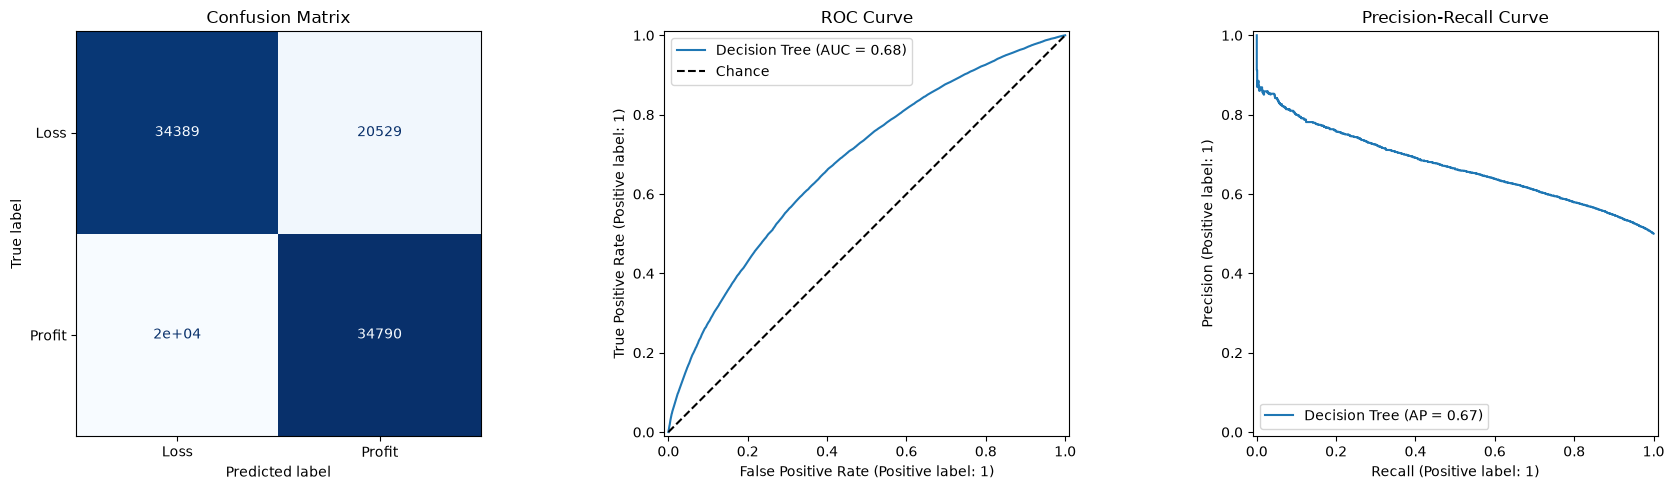

In [11]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5))
ConfusionMatrixDisplay.from_predictions(y_test, test_prediction, display_labels=["Loss", "Profit"], cmap="Blues", colorbar=False, ax=axes[0])
axes[0].set_title("Confusion Matrix")
RocCurveDisplay.from_predictions(y_test, test_probability, name="Decision Tree", ax=axes[1])
axes[1].plot([0, 1], [0, 1], "k--", label="Chance")
axes[1].legend()
axes[1].set_title("ROC Curve")
PrecisionRecallDisplay.from_predictions(y_test, test_probability, name="Decision Tree", ax=axes[2])
axes[2].set_title("Precision-Recall Curve")
plt.tight_layout()
plt.show()

In [12]:
print(confusion_matrix(y_test, test_prediction))

[[34389 20529]
 [20127 34790]]


In [13]:
len(y_test)

109835

## Plotting the Decision Tree
Max depth of 4, you can see how different features are combined into nodes

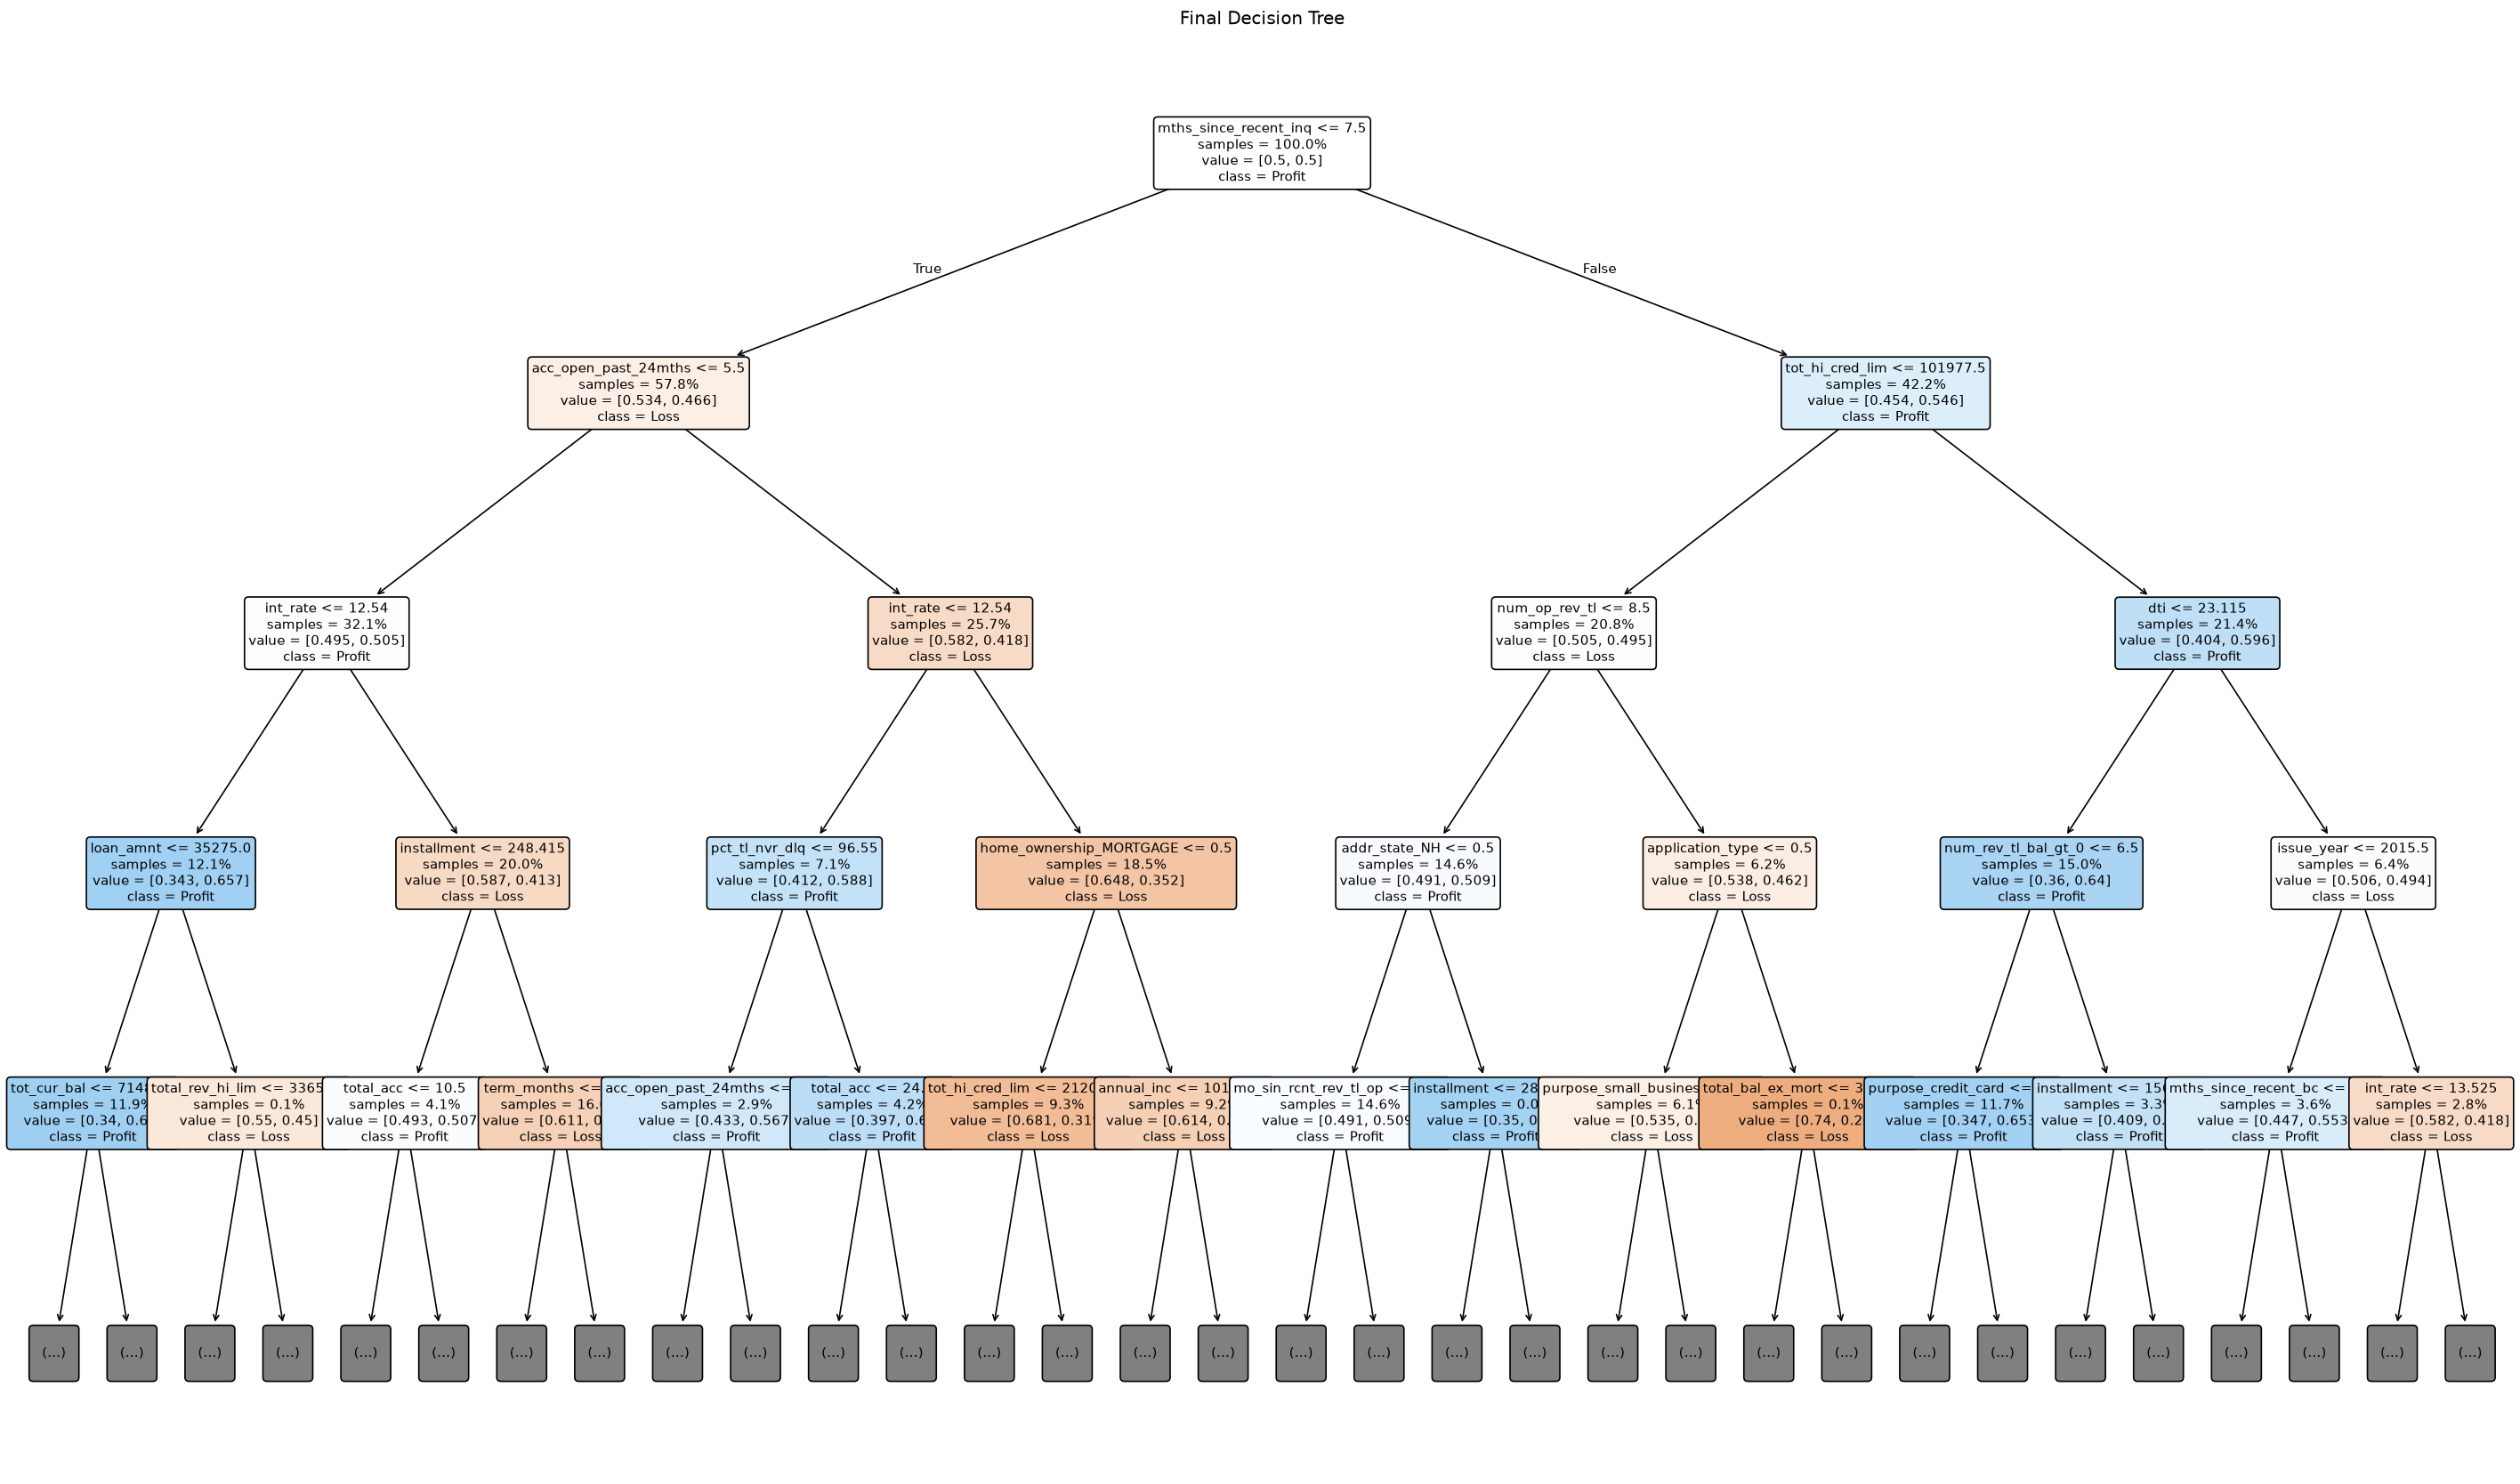

In [14]:
from sklearn.tree import plot_tree

plt.figure(figsize=(24, 14), dpi=120)
plot_tree(
    dt_pipe.named_steps["model"],
    max_depth=4,
    feature_names=X.columns,
    class_names=["Loss", "Profit"],
    filled=True,
    rounded=True,
    proportion=True,
    impurity=False,
    fontsize=9,
)
plt.title("Final Decision Tree")
plt.tight_layout()
plt.show()